# Autoencoder image compression (original coursework code, March 2025)

My original Year 2 Machine Learning submission. The code cells are unchanged.

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F


images = np.load("dataset_LR.npy")


images = images / 255.0


train_x, test_x = train_test_split(images, test_size=0.3, random_state=42)


train_x = torch.tensor(train_x, dtype=torch.float32)
test_x = torch.tensor(test_x, dtype=torch.float32)

In [18]:
class Autoencoder(nn.Module):
    def __init__(self):
        super(Autoencoder, self).__init__()

       
        self.encoder = nn.Sequential(
            nn.Linear(25 * 50, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 32)
        )

     
        self.decoder = nn.Sequential(
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 512),
            nn.ReLU(),
            nn.Linear(512, 25 * 50),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x


autoencoder = Autoencoder()
criterion = nn.MSELoss()
optimizer = optim.Adam(autoencoder.parameters(), lr=0.001)


def train_autoencoder(model, train_x, num_epochs=50, batch_size=50):
    model.train()
    dataset = torch.utils.data.TensorDataset(train_x, train_x)
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)

    for epoch in range(num_epochs):
        epoch_loss = 0
        for batch in dataloader:
            inputs, _ = batch
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, inputs)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        
        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss / len(dataloader):.6f}")


train_autoencoder(autoencoder, train_x)
def evaluate_autoencoder(model, test_x, num_images=5):
    model.eval()
    with torch.no_grad():
        reconstructions = model(test_x[:num_images])
    
    fig, axes = plt.subplots(2, num_images, figsize=(10, 5))
    for i in range(num_images):
        axes[0, i].imshow(test_x[i].reshape(25, 50), cmap="gray")
        axes[0, i].set_title("Original")
        axes[0, i].axis("off")

        axes[1, i].imshow(reconstructions[i].reshape(25, 50), cmap="gray")
        axes[1, i].set_title("Reconstructed")
        axes[1, i].axis("off")

    plt.show()

Epoch [1/50], Loss: 0.051924
Epoch [2/50], Loss: 0.040841
Epoch [3/50], Loss: 0.032342
Epoch [4/50], Loss: 0.026613
Epoch [5/50], Loss: 0.023498
Epoch [6/50], Loss: 0.020748
Epoch [7/50], Loss: 0.019356
Epoch [8/50], Loss: 0.018842
Epoch [9/50], Loss: 0.018241
Epoch [10/50], Loss: 0.016507
Epoch [11/50], Loss: 0.015733
Epoch [12/50], Loss: 0.015124
Epoch [13/50], Loss: 0.014801
Epoch [14/50], Loss: 0.014412
Epoch [15/50], Loss: 0.013647
Epoch [16/50], Loss: 0.013655
Epoch [17/50], Loss: 0.013253
Epoch [18/50], Loss: 0.013047
Epoch [19/50], Loss: 0.012986
Epoch [20/50], Loss: 0.012935
Epoch [21/50], Loss: 0.012834
Epoch [22/50], Loss: 0.012801
Epoch [23/50], Loss: 0.012841
Epoch [24/50], Loss: 0.012763
Epoch [25/50], Loss: 0.012706
Epoch [26/50], Loss: 0.012653
Epoch [27/50], Loss: 0.012538
Epoch [28/50], Loss: 0.012283
Epoch [29/50], Loss: 0.012077
Epoch [30/50], Loss: 0.011844
Epoch [31/50], Loss: 0.012041
Epoch [32/50], Loss: 0.011922
Epoch [33/50], Loss: 0.011673
Epoch [34/50], Loss

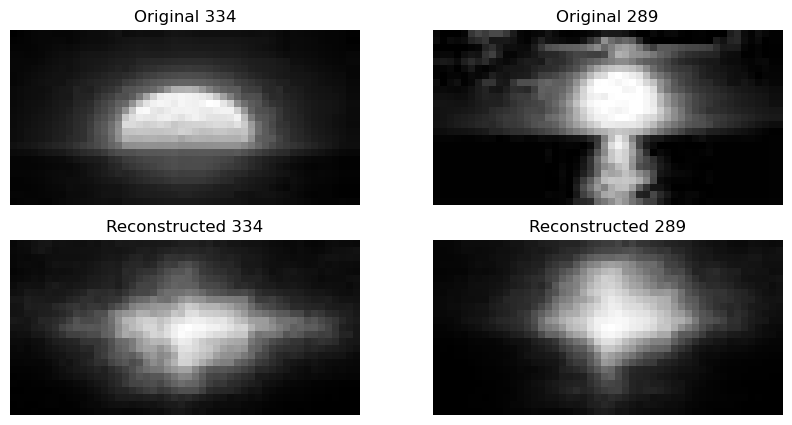

In [19]:
def evaluate_autoencoder(model, test_x, num_images=2):
    model.eval()
    with torch.no_grad():
       
        random_indices = torch.randint(0, test_x.shape[0], (num_images,))
        selected_images = test_x[random_indices]

      
        reconstructions = model(selected_images)

    fig, axes = plt.subplots(2, num_images, figsize=(10, 5))
    for i in range(num_images):
        axes[0, i].imshow(selected_images[i].reshape(25, 50), cmap="gray")
        axes[0, i].axis("off")
        axes[0, i].set_title(f"Original {random_indices[i].item()}")

        axes[1, i].imshow(reconstructions[i].reshape(25, 50), cmap="gray")
        axes[1, i].axis("off")
        axes[1, i].set_title(f"Reconstructed {random_indices[i].item()}")

    plt.show()


evaluate_autoencoder(autoencoder, test_x)
